# Why the CP plateau does not grow as $\sqrt{N}$

## Summary

Doubling the number of stars from 100 to 200 raises the CP SNR by $\sqrt2$ at low signal, but leaves the plateau almost unchanged (ratio 1.006 in a $10^\circ$ field).

When the stars are made statistically independent (off-diagonal $\Gamma_{ab}=0$), the same code gives a plateau of exactly $\sqrt N$. With pulsar-timing correlations plugged in, it reproduces the pulsar-timing result of Romano et al. (2020).

Once the signal dominates the noise, the CP SNR is limited by how many *independent* samples of the GW field the stars provide, not by how many stars there are. The relevant quantity is how correlated two different stars are compared with a star with itself, $\Gamma_{ab}/\Gamma_{aa}$:

| | Same object, $\Gamma_{aa}$ | Two nearby objects, $\Gamma_{ab}$ | Consequence |
|---|---|---|---|
| Pulsars | 1 (Earth term + pulsar term) | at most 0.5 (Earth term only) | each pulsar adds some information no other pulsar has, so the plateau keeps growing with $N$, though more slowly than $\sqrt N$ |
| Stars | $\Gamma(0)$ | $\to\Gamma(0)$ as separation $\to0$ | nearby stars see the same deflection, so extra stars add little new information |

Pulsars carry a pulsar term that is unique to each pulsar. Stars have no equivalent, so every star in the field measures the same realization of the GW field. The plateau is then set by the number of independent GW modes across the field (a few for the full sky, about 2 for a $10^\circ$ field), which is cosmic variance.

**Weak-signal regime is unaffected.** At the physical operating point ($r\approx6\times10^{-11}$ for 1 mas) the CP SNR still grows as $\sqrt N$.

---
The cells below produce the three comparisons behind this summary. Plateau values are quoted in the normalization of Romano et al., $\rho^2=\sum_{ab}[(K\circ K)^{-1}]_{ab}$ with $K_{ab}=\Gamma_{ab}/\Gamma_{aa}$. The values printed by `main.py` are these divided by `POL_FACTOR` = 2.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.getcwd())
import main as M
%matplotlib inline

c = M.POL_FACTOR
COL = {"astro10": "#2a78d6", "astrosky": "#1baf7a", "pta": "#eb6834", "indep": "#eda100"}
LS  = {"astro10": "-", "astrosky": "-.", "pta": "--", "indep": ":"}
MK  = {"astro10": "o", "astrosky": "^", "pta": "s", "indep": "D"}
LAB = {"astro10": "Stars, 10° field", "astrosky": "Stars, full sky",
       "pta": "Pulsars, full sky (Hellings-Downs)", "indep": "Independent objects (control)"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9, "legend.frameon": False,
})

def star_field(N, fov):
    s = M.build_star_positions(None, N, fov, M.RANDOM_SEED)
    th = M.pairwise_theta(s)
    lmin, lmax = M.compute_ell_limits(th, fov)
    return M.gamma_parallel_matrix(th, lmin, lmax, batch_size=20000), lmin, lmax

def hellings_downs(theta):
    # Earth-term HD curve, 0.5 at zero separation; auto-correlation is 1 (pulsar term).
    x = (1 - np.cos(theta)) / 2
    with np.errstate(divide="ignore", invalid="ignore"):
        out = 1.5 * x * np.log(x) - x / 4 + 0.5
    return np.where(x > 0, out, 0.5)

def pulsar_matrix(N, seed=7):
    s = M.build_star_positions(None, N, 360, seed)
    chi = hellings_downs(np.nan_to_num(M.pairwise_theta(s)))
    np.fill_diagonal(chi, np.nan)          # diagonal is set to 1 inside rho_cp_full (normalized)
    return chi

def plateau(gamma_matrix, lmin=2, lmax=50):
    # Signal-dominated CP SNR from main.rho_cp_full (r = 1e3), in Romano normalization.
    return c * M.rho_cp_full([1e3], gamma_matrix, lmin, lmax, verbose=False)[0]

print(f"POL_FACTOR = {c}, NORMALIZED_GAMMA = {M.NORMALIZED_GAMMA}")

POL_FACTOR = 2.0, NORMALIZED_GAMMA = True


## Comparison 1: the CP curve for 100 and 200 stars

Same $10^\circ$ field, same code. At low signal the curves are separated by $\sqrt2$. Once the signal dominates, they meet.

rho_CP(200) / rho_CP(100):  weak signal 1.4142,  physical r 1.4142,  plateau 1.0060   (sqrt 2 = 1.4142)


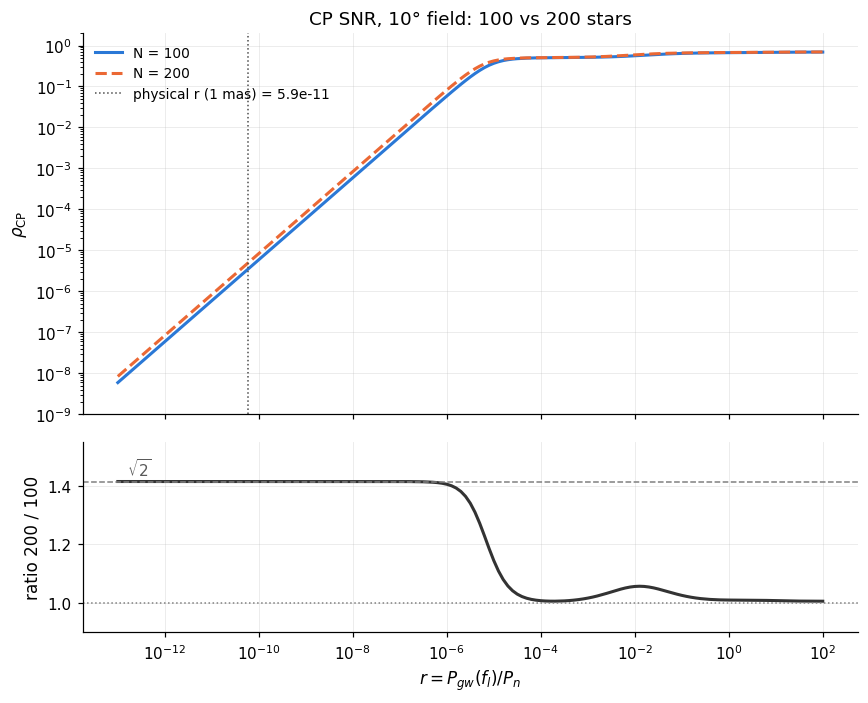

In [2]:
r = np.logspace(-13, 2, 151)
curves = {}
for N in [100, 200]:
    g, lmin, lmax = star_field(N, 10)
    curves[N] = M.rho_cp_full(r, g, lmin, lmax, verbose=False)

ratio = curves[200] / curves[100]
k_weak, k_phys, k_plat = 0, np.argmin(abs(r - M.PHYSICAL_RATIO)), len(r) - 1
print(f"rho_CP(200) / rho_CP(100):  weak signal {ratio[k_weak]:.4f},  physical r {ratio[k_phys]:.4f},  plateau {ratio[k_plat]:.4f}   (sqrt 2 = 1.4142)")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax1.loglog(r, curves[100], color=COL["astro10"], ls="-", label="N = 100")
ax1.loglog(r, curves[200], color=COL["pta"], ls="--", label="N = 200")
ax1.axvline(M.PHYSICAL_RATIO, color="0.3", lw=1, ls=":", label=f"physical r (1 mas) = {M.PHYSICAL_RATIO:.1e}")
ax1.set_ylabel(r"$\rho_{\rm CP}$"); ax1.set_ylim(1e-9, 2); ax1.legend(loc="upper left")
ax1.set_title("CP SNR, 10° field: 100 vs 200 stars")
ax2.semilogx(r, ratio, color="0.2")
ax2.axhline(np.sqrt(2), color="0.5", lw=1, ls="--"); ax2.text(r[2], np.sqrt(2) + 0.02, r"$\sqrt{2}$", color="0.35")
ax2.axhline(1, color="0.5", lw=1, ls=":")
ax2.set_ylim(0.9, 1.55); ax2.set_ylabel("ratio 200 / 100"); ax2.set_xlabel(r"$r = P_{gw}(f_l)/P_n$")
plt.tight_layout(); plt.show()

## Comparison 2: plateau vs number of objects, four cases

All four use the same function, `main.rho_cp_full`. Only the correlation matrix changes:

- **Stars, $10^\circ$ field** and **stars, full sky**: the astrometric $\Gamma$ from `main.py`.
- **Pulsars**: the Hellings-Downs correlation, with auto-correlation 1 from the pulsar term (the case in Romano et al. 2020).
- **Independent objects**: off-diagonal correlation set to zero. This is the only case that gives exactly $\sqrt N$.

case                                     N=25     N=50    N=100    N=200   200/100
Stars, 10° field                         1.37     1.38     1.39     1.40     1.006
Stars, full sky                          2.54     2.63     2.66     2.66     1.003
Pulsars, full sky (Hellings-Downs)       4.19     5.06     5.79     6.31     1.090
Independent objects (control)            5.00     7.07    10.00    14.14     1.414


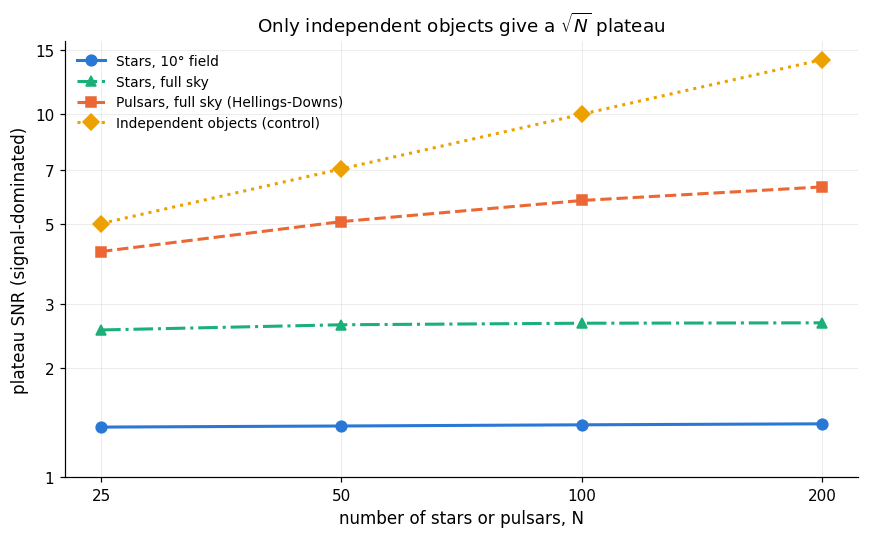

In [3]:
Ns = [25, 50, 100, 200]
res = {k: [] for k in LAB}
for N in Ns:
    g10, lmin, lmax = star_field(N, 10)
    res["astro10"].append(plateau(g10, lmin, lmax))
    gsky, lmin, lmax = star_field(N, 360)
    res["astrosky"].append(plateau(gsky, lmin, lmax))
    res["pta"].append(plateau(pulsar_matrix(N)))
    z = np.zeros((N, N)); np.fill_diagonal(z, np.nan)
    res["indep"].append(plateau(z))

print(f"{'case':<36}" + "".join(f"{'N='+str(N):>9}" for N in Ns) + f"{'200/100':>10}")
for k in LAB:
    v = res[k]
    print(f"{LAB[k]:<36}" + "".join(f"{x:9.2f}" for x in v) + f"{v[3]/v[2]:10.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
for k in LAB:
    ax.loglog(Ns, res[k], color=COL[k], ls=LS[k], marker=MK[k], ms=7, label=LAB[k])
ax.set_xlabel("number of stars or pulsars, N"); ax.set_ylabel("plateau SNR (signal-dominated)")
ax.set_xticks(Ns); ax.set_xticklabels([str(n) for n in Ns])
yt = [1, 2, 3, 5, 7, 10, 15]
ax.set_yticks(yt); ax.set_yticklabels([str(y) for y in yt]); ax.minorticks_off()
ax.set_title(r"Only independent objects give a $\sqrt{N}$ plateau")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**Reading.**
- Independent objects follow $\sqrt N$ exactly. This confirms the code handles the scaling correctly.
- Pulsars keep growing with $N$, because the pulsar term gives each pulsar some information no other pulsar shares. The growth is already slower than $\sqrt N$ (a factor 1.09 from 100 to 200) and keeps slowing, because the shared Earth-term correlation builds up as pulsars are added. A pure $\sqrt N$ plateau needs $N\langle K_{ab}^2\rangle\ll1$, which here means fewer than a few tens of pulsars.
- Stars barely change with $N$. A wider field raises the plateau, because it contains more independent GW modes, but it still does not grow with $N$.

## Comparison 3: why stars and pulsars differ

How strongly two objects are correlated, relative to an object with itself, as a function of their separation.

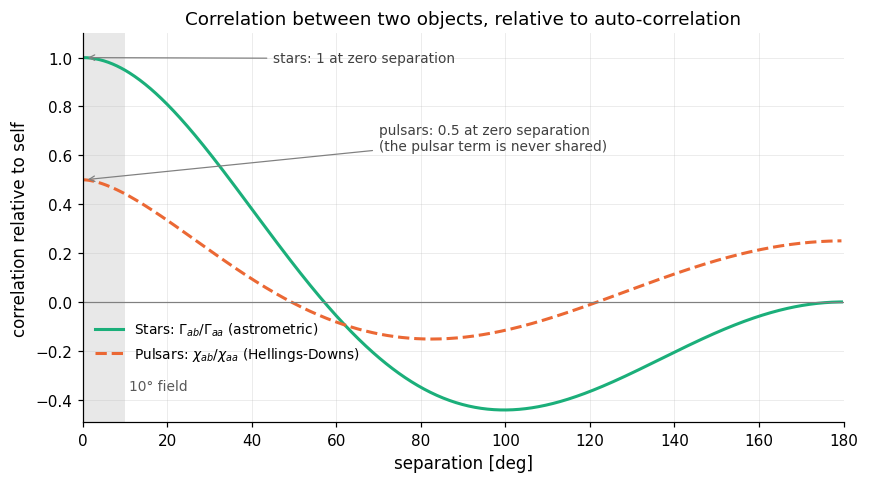

Stars, 10° field     mean (correlation relative to self)^2 over all pairs, N=100: 0.974
Stars, full sky      mean (correlation relative to self)^2 over all pairs, N=100: 0.141
Pulsars, full sky    mean (correlation relative to self)^2 over all pairs, N=100: 0.020


In [4]:
theta_deg = np.linspace(0.05, 179.5, 719)   # stop short of 180 deg, where the kernel's theta=pi branch is special-cased
theta = np.deg2rad(theta_deg)
# Astrometric Gamma, normalized so Gamma(0) = 1; ell range from a full-sky 200-star field
_, lmin_s, lmax_s = star_field(200, 360)
gam_curve = M.gamma_parallel(theta, lmin_s, lmax_s)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(theta_deg, gam_curve, color=COL["astrosky"], ls="-", label=r"Stars: $\Gamma_{ab}/\Gamma_{aa}$ (astrometric)")
ax.plot(theta_deg, hellings_downs(theta), color=COL["pta"], ls="--", label=r"Pulsars: $\chi_{ab}/\chi_{aa}$ (Hellings-Downs)")
ax.axvspan(0, 10, color="0.85", alpha=0.6, lw=0)
ax.text(11, -0.36, "10° field", fontsize=9, color="0.35")
ax.annotate("stars: 1 at zero separation", xy=(0.5, 1.0), xytext=(45, 0.98), fontsize=9, color="0.25",
            arrowprops=dict(arrowstyle="->", color="0.5", lw=0.8))
ax.annotate("pulsars: 0.5 at zero separation\n(the pulsar term is never shared)", xy=(0.5, 0.5), xytext=(70, 0.62),
            fontsize=9, color="0.25", arrowprops=dict(arrowstyle="->", color="0.5", lw=0.8))
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlim(0, 180); ax.set_ylim(min(-0.3, gam_curve.min() - 0.05), 1.1)
ax.set_xlabel("separation [deg]"); ax.set_ylabel("correlation relative to self")
ax.set_title("Correlation between two objects, relative to auto-correlation")
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 0.12))
plt.tight_layout(); plt.show()

iu = lambda n: np.triu_indices(n, 1)
g10, _, _ = star_field(100, 10); gsky, _, _ = star_field(100, 360); chi = pulsar_matrix(100)
for name, mtx in [("Stars, 10° field", g10), ("Stars, full sky", gsky), ("Pulsars, full sky", chi)]:
    print(f"{name:<20} mean (correlation relative to self)^2 over all pairs, N=100: {np.mean(mtx[iu(100)]**2):.3f}")

**Reading.** Two pulsars are at most half as correlated as a pulsar with itself, even at zero separation, because the pulsar term is never shared. Two stars at small separation are almost fully correlated, so in a $10^\circ$ field the mean squared correlation between stars is close to 1. Each additional star then repeats information the field already has.

## Conclusion

- The code is correct. It produces $\sqrt N$ when the physics allows it.
- The CP plateau measures cosmic variance: once the signal dominates, the precision is limited by how many independent samples of the single GW realization the observations contain.
- For pulsars that number keeps growing with $N$ because of the pulsar term, but more slowly than $\sqrt N$ once $N\langle K_{ab}^2\rangle$ approaches 1. 
- More stars still help where it matters for detection: in the weak-signal regime, where the physical operating point lies, the CP SNR grows as $\sqrt N$.

Reference: J. D. Romano, J. S. Hazboun, X. Siemens, A. M. Archibald, arXiv:2012.03804, eqs. (29) to (33).